# PDFT Calculation for H$_3^+$

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

In [2]:
# define geometry
s1, s2 = 1.7 / np.sqrt(3), 0.85
s3 = s1 / 2
mol = fgto.M(atom=f"""
    H {s1} 0 0
    H {-s3} {s2} 0
    H {-s3} {-s2} 0
""", unit='bohr', basis='cc-pvdz', charge=1, 
    fragments={0: [0], 1: [1], 2: [2]},
    ensembles={"charge": {i: {"charges": (1, 0), "weights": (1/3, 2/3)} for i in range(3)}, 
               "spin": [0, 1, 2]})

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -1.32913121


---
## Do PDFT Calculations

### Inversion Method

In [3]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=20, frag_symm='auto')
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

frag_symm: 12 operations; fragments solved: [0] of 3
P-DFT method=inversion xc=PBE fxc=PBE nao=15 grid=105528
  it    1  Ef =    -0.9975259909  dEf =         nan  |dVp| = 9.797e-01


/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/scipy/optimize/_trustregion.py:224: ComplexWarning: Casting complex values to real discards the imaginary part
  p, hits_boundary = m.solve(trust_radius)


  it    2  Ef =    -0.9445623071  dEf =   5.296e-02  |dVp| = 5.884e-01
  it    3  Ef =    -0.8912633481  dEf =   5.330e-02  |dVp| = 3.684e-01
  it    4  Ef =    -0.8600292748  dEf =   3.123e-02  |dVp| = 2.503e-01
  it    5  Ef =    -0.8426037793  dEf =   1.743e-02  |dVp| = 1.889e-01
  it    6  Ef =    -0.8328386033  dEf =   9.765e-03  |dVp| = 1.571e-01
  it    7  Ef =    -0.8272854844  dEf =   5.553e-03  |dVp| = 1.403e-01
  it    8  Ef =    -0.8240696754  dEf =   3.216e-03  |dVp| = 1.310e-01
  it    9  Ef =    -0.8221678275  dEf =   1.902e-03  |dVp| = 1.255e-01
  it   10  Ef =    -0.8210148704  dEf =   1.153e-03  |dVp| = 1.222e-01
  it   11  Ef =    -0.8202938133  dEf =   7.211e-04  |dVp| = 1.200e-01
  it   12  Ef =    -0.8198271782  dEf =   4.666e-04  |dVp| = 1.185e-01
  it   13  Ef =    -0.8195113890  dEf =   3.158e-04  |dVp| = 1.175e-01
  it   14  Ef =    -0.8192862241  dEf =   2.252e-04  |dVp| = 1.168e-01
  it   15  Ef =    -0.8191161073  dEf =   1.701e-04  |dVp| = 1.162e-01
  it  

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 20 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Functional Method

In [4]:
mf2 = pdft.RKS(mol, method='functional-T', maxiter=20, frag_symm='auto')
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}")

frag_symm: 12 operations; fragments solved: [0] of 3
P-DFT method=functional xc=PBE fxc=PBE nao=15 grid=105528
  it    1  Ef =    -0.9975259909  dEf =         nan  |dVp| = 1.007e+00
  it    2  Ef =    -0.9350640084  dEf =   6.246e-02  |dVp| = 5.257e-01
  it    3  Ef =    -0.8822913899  dEf =   5.277e-02  |dVp| = 3.145e-01
  it    4  Ef =    -0.8576679660  dEf =   2.462e-02  |dVp| = 2.485e-01
  it    5  Ef =    -0.8467777015  dEf =   1.089e-02  |dVp| = 2.255e-01
  it    6  Ef =    -0.8418126222  dEf =   4.965e-03  |dVp| = 2.109e-01
  it    7  Ef =    -0.8393441037  dEf =   2.469e-03  |dVp| = 1.986e-01
  it    8  Ef =    -0.8379263038  dEf =   1.418e-03  |dVp| = 1.879e-01
  it    9  Ef =    -0.8369561706  dEf =   9.701e-04  |dVp| = 1.785e-01
  it   10  Ef =    -0.8361827741  dEf =   7.734e-04  |dVp| = 1.704e-01
  it   11  Ef =    -0.8355019582  dEf =   6.808e-04  |dVp| = 1.632e-01
  it   12  Ef =    -0.8348711299  dEf =   6.308e-04  |dVp| = 1.569e-01
  it   13  Ef =    -0.8342737477  dEf

### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=30, frag_symm='auto')
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

frag_symm: 12 operations; fragments solved: [0] of 3
P-DFT method=reference xc=PBE fxc=PBE nao=15 grid=105528
  it    1  Ef =    -0.9975259909  dEf =         nan  |dVp| = 7.365e-02  L1 = 9.555e-01
  it    2  Ef =    -0.9924952731  dEf =   5.031e-03  |dVp| = 6.231e-02  L1 = 7.754e-01
  it    3  Ef =    -0.9832427340  dEf =   9.253e-03  |dVp| = 5.437e-02  L1 = 6.543e-01
  it    4  Ef =    -0.9735796982  dEf =   9.663e-03  |dVp| = 4.836e-02  L1 = 5.679e-01
  it    5  Ef =    -0.9645868042  dEf =   8.993e-03  |dVp| = 4.362e-02  L1 = 5.031e-01
  it    6  Ef =    -0.9565086749  dEf =   8.078e-03  |dVp| = 3.975e-02  L1 = 4.527e-01
  it    7  Ef =    -0.9493286830  dEf =   7.180e-03  |dVp| = 3.653e-02  L1 = 4.124e-01
  it    8  Ef =    -0.9429545000  dEf =   6.374e-03  |dVp| = 3.379e-02  L1 = 3.794e-01
  it    9  Ef =    -0.9372804024  dEf =   5.674e-03  |dVp| = 3.143e-02  L1 = 3.518e-01
  it   10  Ef =    -0.9322077764  dEf =   5.073e-03  |dVp| = 2.938e-02  L1 = 3.285e-01
  it   11  Ef =    -

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 30 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot densities and partition potential

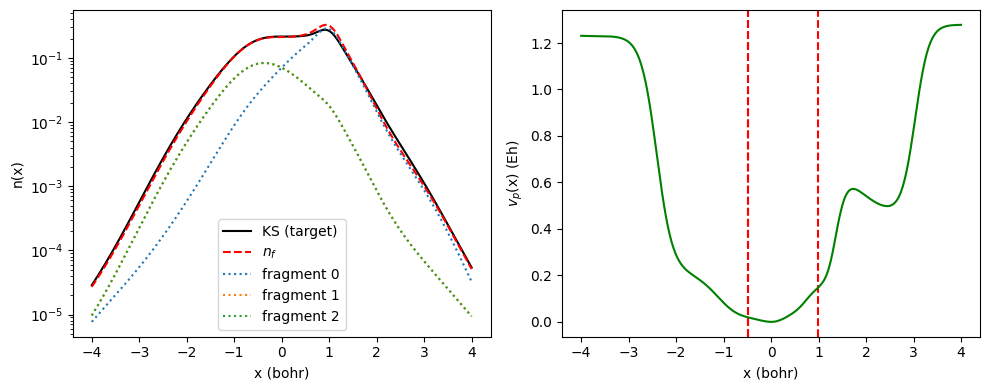

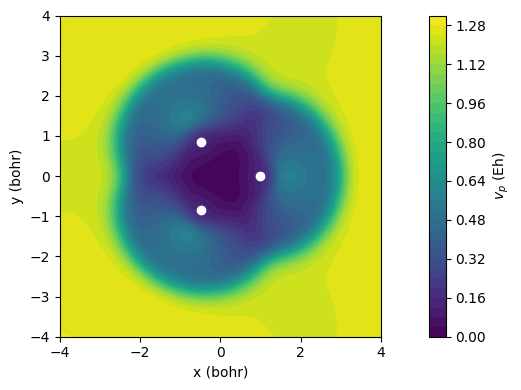

In [6]:
# 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_i = []
for i in range(3): n_i += [mf1.eval_density(line, frag=i)] # fragment densities
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
for i in range(3): ax[0].semilogy(x, n_i[i], ':', label=f"fragment {i}")
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()